In [ ]:
import numpy as np
import random 

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [98]:
SEED = 123
rng = np.random.default_rng(SEED)

N_CITIES = 20

In [ ]:
def initialize_distance_matrix(n_cities: int = 20) -> np.ndarray:
    dist_matrix = rng.integers(1, 30, size=(n_cities, n_cities))
    np.fill_diagonal(dist_matrix, 0)

    return dist_matrix

def initialize_population(pop_size: int = 100, n_cities: int = 20) -> list[list[int]]:
    population = []

    for _ in range(pop_size):
        paths = list(range(1, n_cities))
        rng.shuffle(paths)
        population.append(paths)

    return population

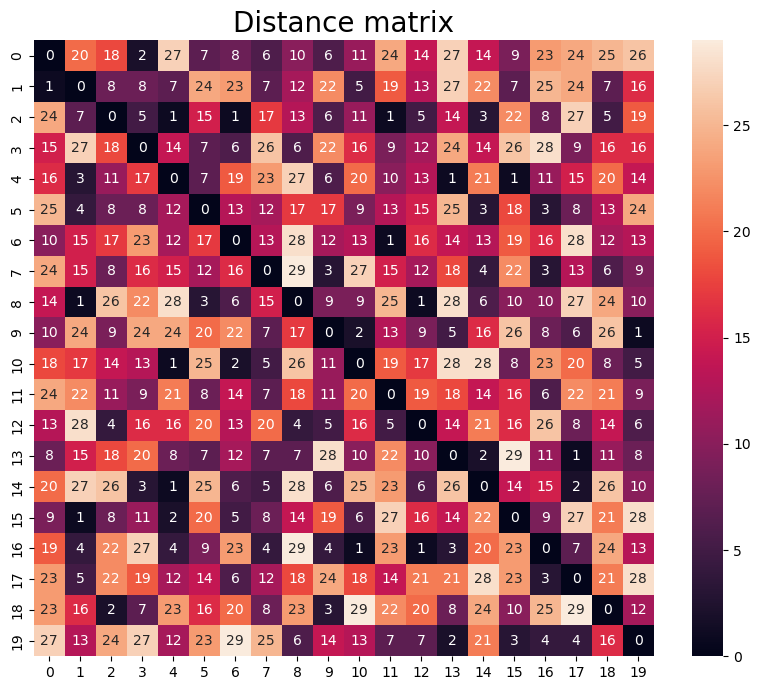

In [ ]:
dist_matrix = initialize_distance_matrix(N_CITIES)

plt.figure(figsize=(10,8))
plt.title('Distance matrix', fontsize=20)
sns.heatmap(dist_matrix, annot=True)
plt.show()

In [86]:
def _decode_path(path: list[int]) -> list[int]:
    return [0] + path + [0]

def calculate_path_cost(path: list[int], dist_matrix: np.ndarray) -> int:
    route = _decode_path(path)

    total_cost = 0
    for i in range(len(route) - 1):
        total_cost += dist_matrix[route[i]][route[i+1]]

    return int(total_cost)

def evaluate_population(population: list[list[int]], dist_matrix: np.ndarray):
    costs = []

    for path in population:
        costs.append(calculate_path_cost(path, dist_matrix))

    return costs

In [ ]:
population = initialize_population(n_cities=N_CITIES)

Dwie metody selekcji - turniejowa i ruletkowa; można na dalszym etapie porównać, która da lepsze rezultaty.

In [ ]:
def tournament_selection(population: list[list[int]], dist_matrix: np.ndarray, k: int = 3) -> list[int]:
    if not population:
        raise ValueError('Population cannot be empty!')
    
    if k > len(population):
        raise ValueError(f'Tournament size {k} must be smaller than the population size!')
    
    costs = evaluate_population(population, dist_matrix)

    tournament_indices = rng.choice(len(population), size=k, replace=False) 
    winner_idx = min(tournament_indices, key = lambda i: costs[i]) 
        
    return population[winner_idx].copy()

def roulette_wheel_selection(population: list[list[int]], dist_matrix: np.ndarray, k: int = 3) -> list[int]:
    if not population:
        raise ValueError('Population cannot be empty!')
    
    costs = evaluate_population(population, dist_matrix)
    costs = np.asarray(costs, dtype=np.float32)

    max_cost = np.max(costs)
    weights = (max_cost - costs) + 1

    probabiliteies = weights / np.sum(weights)
 
    winner_idx = rng.choice(len(population), p=probabiliteies) #

    return population[winner_idx]



In [ ]:
#parent1 = tournament_selection(population,dist_matrix)
#parent2 = tournament_selection(population,dist_matrix)